In [25]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.models as models

import numpy as np
import random
from pathlib import Path

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Select device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch version:", torch.__version__)
print("Torchvision version:", __import__("torchvision").__version__)
print("Device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
    print("Available VRAM:", round(
        torch.cuda.get_device_properties(0).total_memory / (1024 ** 3), 2
    ), "GB")
    

PyTorch version: 2.14.1+cu130
Torchvision version: 0.29.1+cu130
Device: cuda
GPU: NVIDIA GeForce RTX 3050 Laptop GPU
Available VRAM: 4.0 GB


In [26]:
# Load ResNet18 with pretrained ImageNet weights
weights = models.ResNet18_Weights.DEFAULT

model = models.resnet18(weights=weights)

# Replace the final classification layer
num_features = model.fc.in_features
model.fc = nn.Linear(num_features, 3)

# Move model to GPU
model = model.to(device)

print(model)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_sta

In [27]:
from torchvision import transforms

imagenet_normalize = transforms.Normalize(
    mean=[0.485, 0.456, 0.406],
    std=[0.229, 0.224, 0.225]
)

print("ImageNet normalization configured.")

ImageNet normalization configured.


In [28]:
import pandas as pd

# Project paths
dataset_path = Path("../dataset/brain_tumor_dataset")
processed_dir = dataset_path.parent / "processed"

# Load the existing patient-level split manifest
split_manifest = pd.read_csv(
    dataset_path / "splits" / "split_manifest.csv"
)

print("Manifest loaded:", len(split_manifest), "images")
print("\nSplit distribution:")
print(split_manifest["split"].value_counts())

print("\nClass distribution:")
print(split_manifest.groupby(["split", "label_name"]).size())

Manifest loaded: 3064 images

Split distribution:
split
train         1991
test           542
validation     531
Name: count, dtype: int64

Class distribution:
split       label_name
test        glioma        245
            meningioma    112
            pituitary     185
train       glioma        958
            meningioma    443
            pituitary     590
validation  glioma        223
            meningioma    153
            pituitary     155
dtype: int64


In [29]:
from torch.utils.data import Dataset, DataLoader
from PIL import Image

def preprocess_mri(image_path):
    with Image.open(image_path) as img:
        img = img.resize((224, 224), Image.Resampling.BILINEAR)
        pixels = np.array(img, dtype=np.float32)

    lower = np.percentile(pixels, 1)
    upper = np.percentile(pixels, 99)

    pixels = np.clip(pixels, lower, upper)
    pixels = (pixels - lower) / (upper - lower + 1e-8)

    return pixels


class BrainMRIDataset(Dataset):
    def __init__(self, manifest, split, processed_dir):
        self.records = manifest[
            manifest["split"] == split
        ].reset_index(drop=True)

        self.processed_dir = processed_dir

        self.class_to_idx = {
            "glioma": 0,
            "meningioma": 1,
            "pituitary": 2
        }

    def __len__(self):
        return len(self.records)

    def __getitem__(self, index):
        row = self.records.iloc[index]

        image_path = (
            self.processed_dir
            / row["split"]
            / row["label_name"]
            / f"{int(row['id'])}.png"
        )

        pixels = preprocess_mri(image_path)

        image = torch.from_numpy(pixels).unsqueeze(0)
        image = image.repeat(3, 1, 1)

        image = imagenet_normalize(image)

        label = self.class_to_idx[row["label_name"]]

        return image, label

In [30]:
train_dataset = BrainMRIDataset(
    split_manifest, "train", processed_dir
)

val_dataset = BrainMRIDataset(
    split_manifest, "validation", processed_dir
)

test_dataset = BrainMRIDataset(
    split_manifest, "test", processed_dir
)

# Fetch one training sample
image, label = train_dataset[0]

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Test images:", len(test_dataset))

print("\nSample image shape:", image.shape)
print("Image data type:", image.dtype)
print("Image minimum:", image.min().item())
print("Image maximum:", image.max().item())
print("Sample label:", label)

Training images: 1991
Validation images: 531
Test images: 542

Sample image shape: torch.Size([3, 224, 224])
Image data type: torch.float32
Image minimum: -2.1179039478302
Image maximum: 2.640000104904175
Sample label: 1


In [31]:
train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Training batches: 125
Validation batches: 34
Test batches: 34


In [32]:
images, labels = next(iter(train_loader))

print("Batch image shape:", images.shape)
print("Batch label shape:", labels.shape)

print("Image dtype:", images.dtype)
print("Label dtype:", labels.dtype)

print("\nLabels in batch:")
print(labels)

print("\nGPU memory allocated:",
      round(torch.cuda.memory_allocated() / (1024 ** 2), 2), "MB")

Batch image shape: torch.Size([16, 3, 224, 224])
Batch label shape: torch.Size([16])
Image dtype: torch.float32
Label dtype: torch.int64

Labels in batch:
tensor([0, 0, 0, 0, 1, 1, 2, 0, 0, 0, 0, 0, 1, 1, 2, 0])

GPU memory allocated: 368.48 MB


In [33]:
from collections import Counter

train_labels = [
    train_dataset.class_to_idx[label]
    for label in train_dataset.records["label_name"]
]

class_counts = Counter(train_labels)

num_classes = 3
total_samples = len(train_labels)

class_weights = torch.tensor(
    [
        total_samples / (num_classes * class_counts[i])
        for i in range(num_classes)
    ],
    dtype=torch.float32
).to(device)

print("Class counts:", class_counts)
print("Class weights:", class_weights)

Class counts: Counter({0: 958, 2: 590, 1: 443})
Class weights: tensor([0.6928, 1.4981, 1.1249], device='cuda:0')


In [34]:
# Loss function with class balancing
criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

# Optimizer
optimizer = optim.AdamW(
    model.parameters(),
    lr=0.0001,
    weight_decay=0.0001
)

print("Loss function:", criterion)
print("Optimizer:", optimizer)

Loss function: CrossEntropyLoss()
Optimizer: AdamW (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: True
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.0001
    maximize: False
    weight_decay: 0.0001
)


In [35]:
# Training configuration
NUM_EPOCHS = 15

best_val_loss = float("inf")

# Store training history
history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

# Checkpoint directory
checkpoint_dir = Path("../models")
checkpoint_dir.mkdir(parents=True, exist_ok=True)

print("Epochs:", NUM_EPOCHS)
print("Checkpoint directory:", checkpoint_dir.resolve())

Epochs: 15
Checkpoint directory: C:\Users\vanga\OneDrive\Desktop\project me\BrainSight\models


In [36]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy


def validate_one_epoch(model, loader, criterion, device):
    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy

In [37]:
import time

for epoch in range(NUM_EPOCHS):
    start_time = time.time()

    train_loss, train_accuracy = train_one_epoch(
        model, train_loader, criterion, optimizer, device
    )

    val_loss, val_accuracy = validate_one_epoch(
        model, val_loader, criterion, device
    )

    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)

    # Save the best model based on validation loss
    if val_loss < best_val_loss:
        best_val_loss = val_loss

        torch.save(
            {
                "epoch": epoch + 1,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "val_loss": val_loss,
                "val_accuracy": val_accuracy
            },
            checkpoint_dir / "best_resnet18.pth"
        )

        saved = " [Best model saved]"
    else:
        saved = ""

    elapsed_time = time.time() - start_time

    print(
        f"Epoch [{epoch + 1}/{NUM_EPOCHS}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.4f} | "
        f"Time: {elapsed_time:.1f}s"
        f"{saved}"
    )

Epoch [1/15] Train Loss: 0.2801 | Train Acc: 0.8905 | Val Loss: 0.3848 | Val Acc: 0.8644 | Time: 37.5s [Best model saved]
Epoch [2/15] Train Loss: 0.0741 | Train Acc: 0.9744 | Val Loss: 0.2449 | Val Acc: 0.9134 | Time: 37.9s [Best model saved]
Epoch [3/15] Train Loss: 0.0265 | Train Acc: 0.9930 | Val Loss: 0.3378 | Val Acc: 0.9153 | Time: 35.2s
Epoch [4/15] Train Loss: 0.0298 | Train Acc: 0.9930 | Val Loss: 0.2739 | Val Acc: 0.9171 | Time: 35.3s
Epoch [5/15] Train Loss: 0.0216 | Train Acc: 0.9935 | Val Loss: 0.2314 | Val Acc: 0.9247 | Time: 36.4s [Best model saved]
Epoch [6/15] Train Loss: 0.0102 | Train Acc: 0.9975 | Val Loss: 0.3235 | Val Acc: 0.9171 | Time: 38.4s
Epoch [7/15] Train Loss: 0.0049 | Train Acc: 0.9990 | Val Loss: 0.3247 | Val Acc: 0.9096 | Time: 35.4s
Epoch [8/15] Train Loss: 0.0199 | Train Acc: 0.9930 | Val Loss: 0.4212 | Val Acc: 0.8795 | Time: 35.7s
Epoch [9/15] Train Loss: 0.0437 | Train Acc: 0.9864 | Val Loss: 0.2868 | Val Acc: 0.9002 | Time: 38.2s
Epoch [10/15] Tr

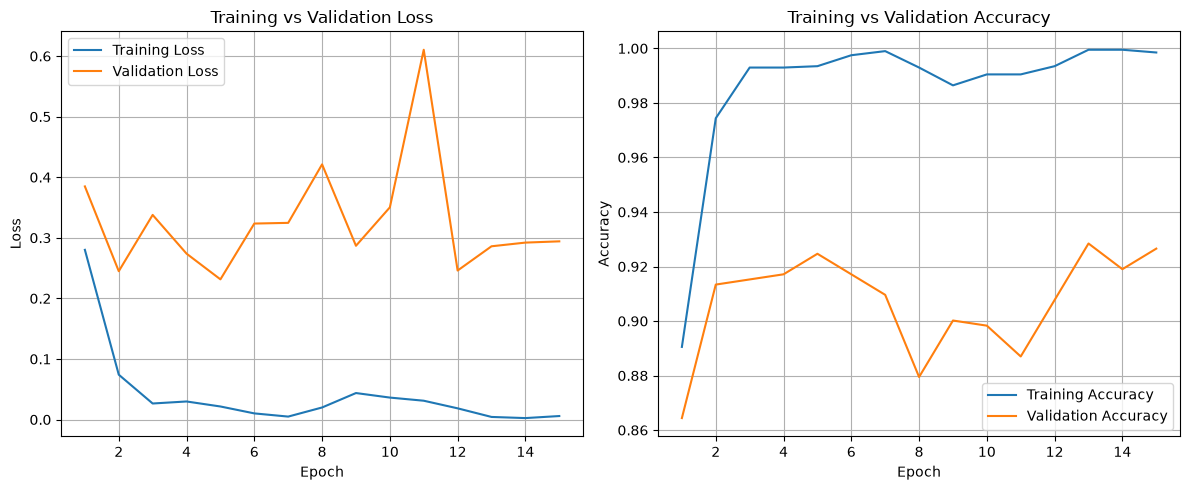

In [38]:
import matplotlib.pyplot as plt

epochs = range(1, NUM_EPOCHS + 1)

plt.figure(figsize=(12, 5))

# Loss curves
plt.subplot(1, 2, 1)
plt.plot(epochs, history["train_loss"], label="Training Loss")
plt.plot(epochs, history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True)

# Accuracy curves
plt.subplot(1, 2, 2)
plt.plot(epochs, history["train_accuracy"], label="Training Accuracy")
plt.plot(epochs, history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [39]:
checkpoint_path = checkpoint_dir / "best_resnet18.pth"

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("Best checkpoint loaded successfully!")
print("Best epoch:", checkpoint["epoch"])
print("Validation loss:", checkpoint["val_loss"])
print("Validation accuracy:", checkpoint["val_accuracy"])

Best checkpoint loaded successfully!
Best epoch: 5
Validation loss: 0.2314202954856779
Validation accuracy: 0.9246704331450094


In [40]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)

        predictions = outputs.argmax(dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.numpy())

accuracy = accuracy_score(all_labels, all_predictions)
precision = precision_score(all_labels, all_predictions, average="macro")
recall = recall_score(all_labels, all_predictions, average="macro")
f1 = f1_score(all_labels, all_predictions, average="macro")

print("TEST SET RESULTS")
print("----------------")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"Macro F1:  {f1:.4f}")

print("\nClassification Report:")
print(classification_report(
    all_labels,
    all_predictions,
    target_names=["Glioma", "Meningioma", "Pituitary"],
    digits=4
))

print("\nConfusion Matrix:")
print(confusion_matrix(all_labels, all_predictions))

TEST SET RESULTS
----------------
Accuracy:  0.9502
Precision: 0.9477
Recall:    0.9445
Macro F1:  0.9450

Classification Report:
              precision    recall  f1-score   support

      Glioma     0.9380    0.9878    0.9622       245
  Meningioma     0.9052    0.9375    0.9211       112
   Pituitary     1.0000    0.9081    0.9518       185

    accuracy                         0.9502       542
   macro avg     0.9477    0.9445    0.9450       542
weighted avg     0.9524    0.9502    0.9502       542


Confusion Matrix:
[[242   3   0]
 [  7 105   0]
 [  9   8 168]]


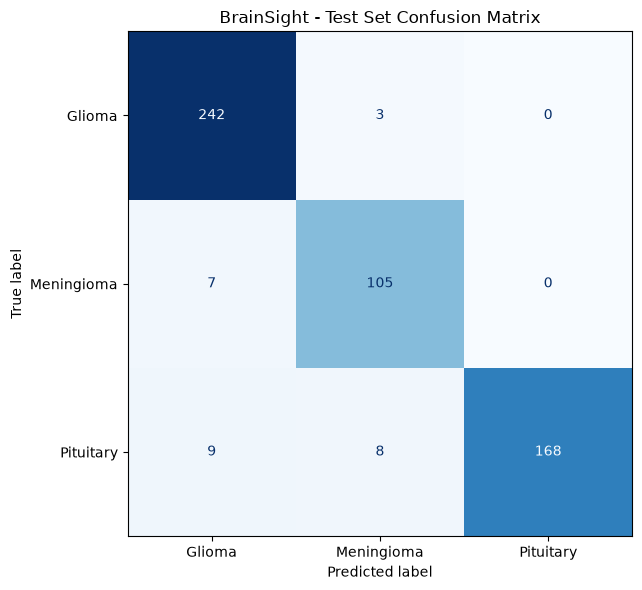

In [41]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

class_names = ["Glioma", "Meningioma", "Pituitary"]

cm = confusion_matrix(all_labels, all_predictions)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(7, 6))

display.plot(
    cmap="Blues",
    values_format="d",
    ax=ax,
    colorbar=False
)

plt.title("BrainSight - Test Set Confusion Matrix")
plt.tight_layout()
plt.show()

In [42]:
class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer

        self.activations = None
        self.gradients = None

        self.target_layer.register_forward_hook(
            self.save_activations
        )

        self.target_layer.register_full_backward_hook(
            self.save_gradients
        )

    def save_activations(self, module, input, output):
        self.activations = output.detach()

    def save_gradients(self, module, grad_input, grad_output):
        self.gradients = grad_output[0].detach()

    def generate(self, image, class_index=None):
        self.model.eval()
        self.model.zero_grad()

        output = self.model(image)

        if class_index is None:
            class_index = output.argmax(dim=1).item()

        score = output[:, class_index]
        score.backward()

        weights = self.gradients.mean(dim=(2, 3), keepdim=True)

        cam = (weights * self.activations).sum(dim=1)
        cam = torch.relu(cam)

        cam = cam.squeeze()

        cam = cam - cam.min()
        cam = cam / (cam.max() + 1e-8)

        return cam.cpu().numpy(), class_index


grad_cam = GradCAM(
    model,
    model.layer4[-1]
)

print("Grad-CAM initialized successfully.")

Grad-CAM initialized successfully.


In [43]:
import random

# Select one random image from the test set
sample_index = random.randrange(len(test_dataset))

image, true_label = test_dataset[sample_index]

image = image.unsqueeze(0).to(device)

# Generate Grad-CAM heatmap
heatmap, predicted_label = grad_cam.generate(image)

class_names = ["Glioma", "Meningioma", "Pituitary"]

print("Sample index:", sample_index)
print("Actual class:", class_names[true_label])
print("Predicted class:", class_names[predicted_label])
print("Heatmap shape:", heatmap.shape)
print("Heatmap range:", heatmap.min(), "to", heatmap.max())

Sample index: 114
Actual class: Glioma
Predicted class: Glioma
Heatmap shape: (7, 7)
Heatmap range: 0.0 to 0.99999994


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.0000000238418578].


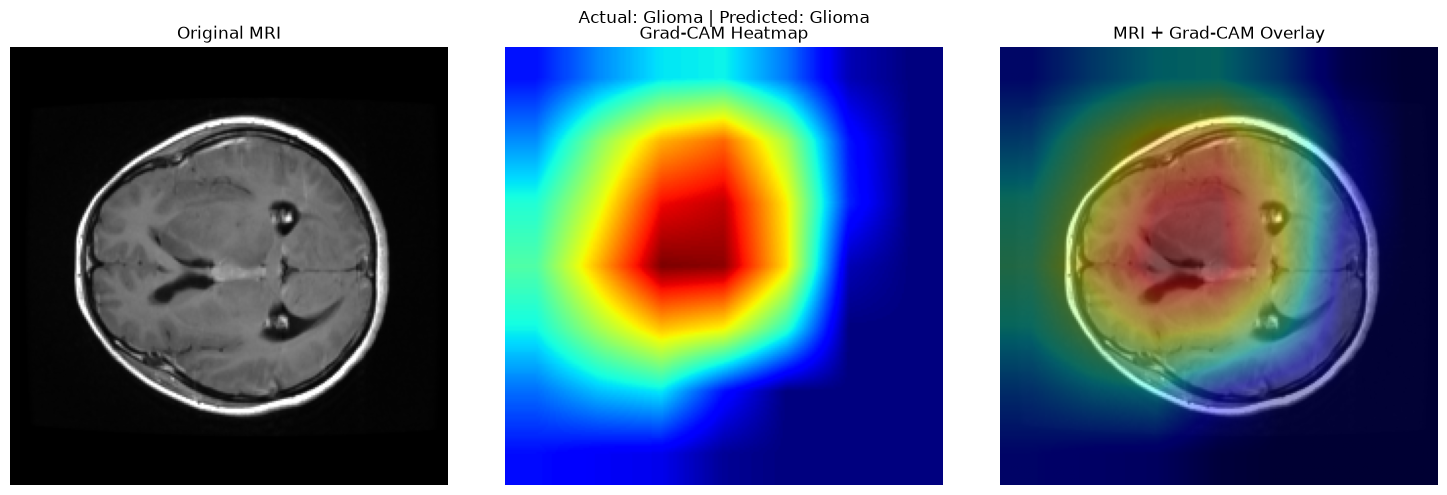

In [44]:
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

# Resize the Grad-CAM heatmap to 224x224
heatmap_resized = np.array(
    Image.fromarray(heatmap.astype(np.float32))
    .resize((224, 224), Image.Resampling.BILINEAR)
)

# Load the original MRI image
row = test_dataset.records.iloc[sample_index]

image_path = (
    processed_dir
    / "test"
    / row["label_name"]
    / f"{int(row['id'])}.png"
)

original_image = preprocess_mri(image_path)

# Convert grayscale MRI into RGB
original_rgb = np.stack(
    [original_image] * 3,
    axis=-1
)

# Apply color map to heatmap
heatmap_color = plt.get_cmap("jet")(heatmap_resized)[..., :3]

# Blend MRI and heatmap
overlay = (
    0.6 * original_rgb +
    0.4 * heatmap_color
)

# Display results
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(original_rgb)
plt.title("Original MRI")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(heatmap_resized, cmap="jet")
plt.title("Grad-CAM Heatmap")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(overlay)
plt.title("MRI + Grad-CAM Overlay")
plt.axis("off")

plt.suptitle(
    f"Actual: {class_names[true_label]} | "
    f"Predicted: {class_names[predicted_label]}"
)

plt.tight_layout()
plt.show()

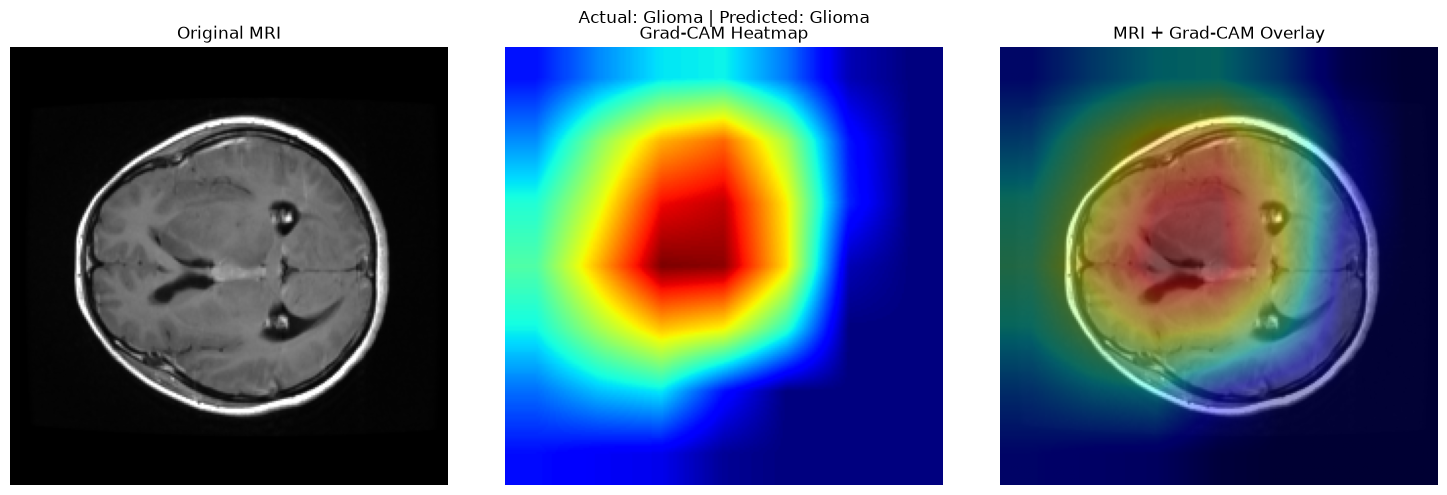

In [45]:
original_rgb = np.clip(original_rgb, 0.0, 1.0)
overlay = np.clip(overlay, 0.0, 1.0)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(original_rgb)
plt.title("Original MRI")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(heatmap_resized, cmap="jet")
plt.title("Grad-CAM Heatmap")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(overlay)
plt.title("MRI + Grad-CAM Overlay")
plt.axis("off")

plt.suptitle(
    f"Actual: {class_names[true_label]} | "
    f"Predicted: {class_names[predicted_label]}"
)

plt.tight_layout()
plt.show()

In [46]:
class_names = ["Glioma", "Meningioma", "Pituitary"]

selected_samples = {}

# Find one correctly classified sample from each class
for class_index, class_name in enumerate(class_names):
    for i, (actual, predicted) in enumerate(
        zip(all_labels, all_predictions)
    ):
        if actual == class_index and predicted == class_index:
            selected_samples[class_name] = i
            break

# Find a Pituitary image incorrectly predicted as Meningioma
for i, (actual, predicted) in enumerate(
    zip(all_labels, all_predictions)
):
    if actual == 2 and predicted == 1:
        selected_samples["Pituitary_Misclassified"] = i
        break

# Display selected samples
for name, index in selected_samples.items():
    print(
        f"{name}: Test index {index} | "
        f"Actual: {class_names[all_labels[index]]} | "
        f"Predicted: {class_names[all_predictions[index]]}"
    )

Glioma: Test index 112 | Actual: Glioma | Predicted: Glioma
Meningioma: Test index 0 | Actual: Meningioma | Predicted: Meningioma
Pituitary: Test index 135 | Actual: Pituitary | Predicted: Pituitary
Pituitary_Misclassified: Test index 183 | Actual: Pituitary | Predicted: Meningioma


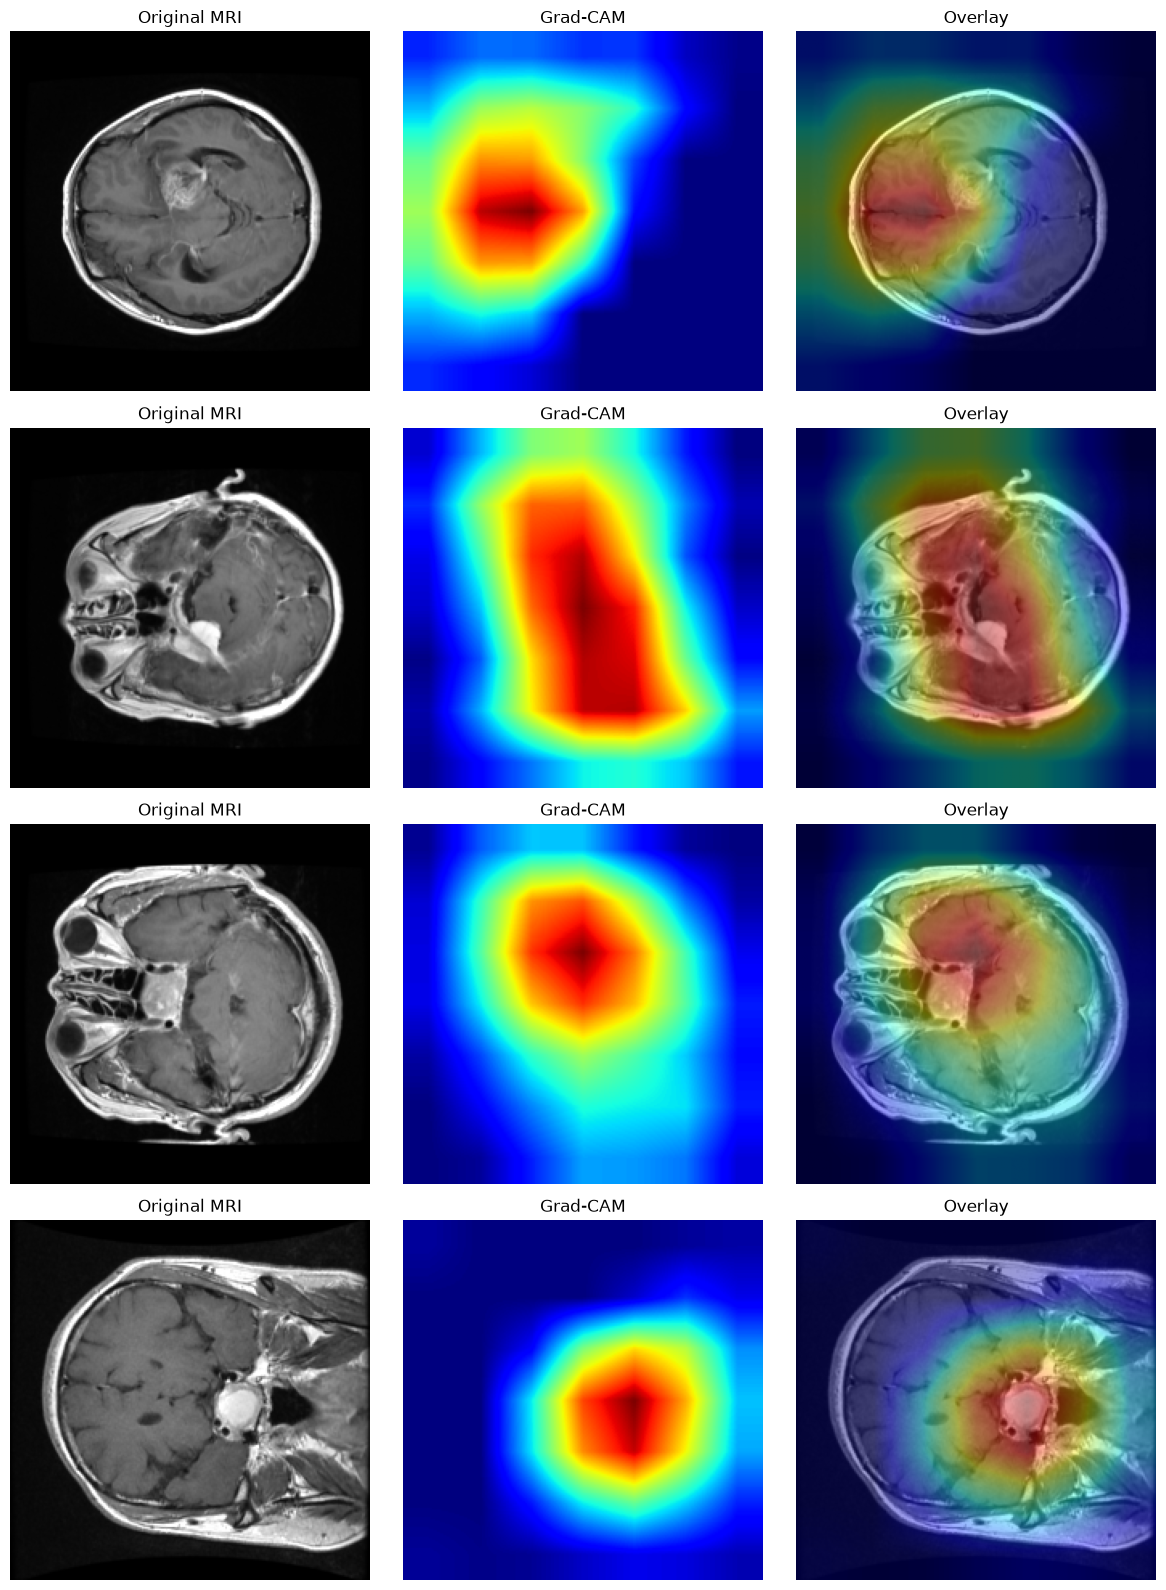

In [47]:
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

fig, axes = plt.subplots(4, 3, figsize=(12, 16))

for row_index, (name, index) in enumerate(selected_samples.items()):

    image, true_label = test_dataset[index]
    image = image.unsqueeze(0).to(device)

    heatmap, predicted_label = grad_cam.generate(image)

    heatmap_resized = np.array(
        Image.fromarray(heatmap.astype(np.float32))
        .resize((224, 224), Image.Resampling.BILINEAR)
    )

    record = test_dataset.records.iloc[index]

    image_path = (
        processed_dir
        / "test"
        / record["label_name"]
        / f"{int(record['id'])}.png"
    )

    original_image = preprocess_mri(image_path)

    original_rgb = np.stack(
        [original_image] * 3,
        axis=-1
    )

    heatmap_color = plt.get_cmap("jet")(
        heatmap_resized
    )[..., :3]

    overlay = np.clip(
        0.6 * original_rgb + 0.4 * heatmap_color,
        0.0,
        1.0
    )

    axes[row_index, 0].imshow(original_rgb)
    axes[row_index, 0].set_title("Original MRI")

    axes[row_index, 1].imshow(
        heatmap_resized,
        cmap="jet"
    )
    axes[row_index, 1].set_title("Grad-CAM")

    axes[row_index, 2].imshow(overlay)
    axes[row_index, 2].set_title("Overlay")

    for ax in axes[row_index]:
        ax.axis("off")

    axes[row_index, 0].set_ylabel(
        f"{name}\nActual: {class_names[true_label]}\n"
        f"Predicted: {class_names[predicted_label]}",
        fontsize=10
    )

plt.tight_layout()
plt.show()

In [75]:
import sys

print("Python executable:")
print(sys.executable)

print("\nPyTorch version:")
print(torch.__version__)

print("\nTorch location:")
print(torch.__file__)

Python executable:
C:\Users\vanga\OneDrive\Desktop\project me\BrainSight\venv\Scripts\python.exe

PyTorch version:
2.14.1+cu130

Torch location:
C:\Users\vanga\OneDrive\Desktop\project me\BrainSight\venv\Lib\site-packages\torch\__init__.py


In [105]:

import torchvision.transforms as T
from torch.utils.data import Dataset, DataLoader

# Mild augmentation applied only to training images
augmentation = T.RandomAffine(
    degrees=8,
    translate=(0.04, 0.04),
    scale=(0.95, 1.05),
    fill=0
)

class AugmentedDataset(Dataset):
    def __init__(self, original_dataset, transform):
        self.original_dataset = original_dataset
        self.transform = transform

    def __len__(self):
        return len(self.original_dataset)

    def __getitem__(self, index):
        image, label = self.original_dataset[index]
        image = self.transform(image)
        return image, label

# Create augmented training dataset
augmented_train_dataset = AugmentedDataset(
    train_dataset,
    augmentation
)

# Keep validation and test datasets unchanged
augmented_train_loader = DataLoader(
    augmented_train_dataset,
    batch_size=16,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

print("Augmented training dataset:", len(augmented_train_dataset))
print("Validation dataset:", len(val_dataset))
print("Test dataset:", len(test_dataset))
print("Training batches:", len(augmented_train_loader))


Augmented training dataset: 1991
Validation dataset: 531
Test dataset: 542
Training batches: 125


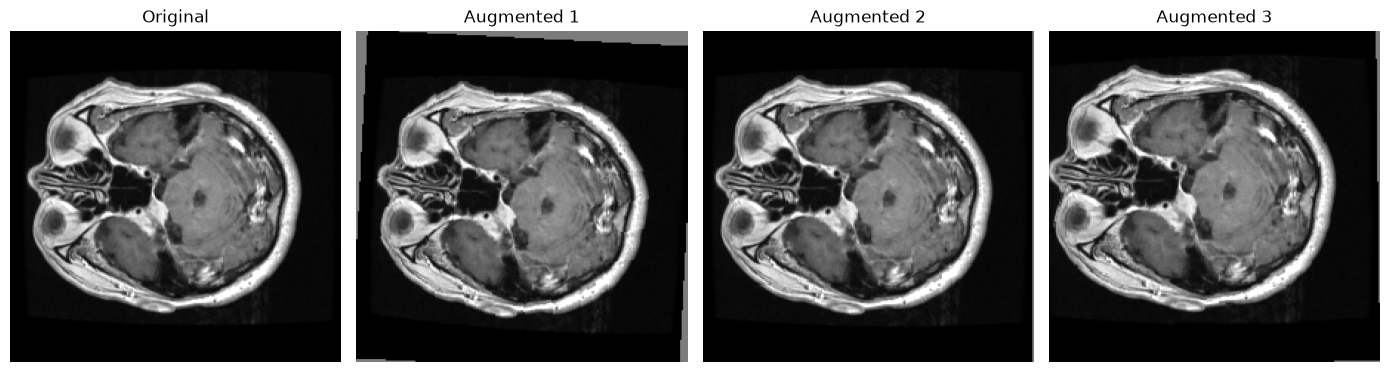

In [107]:
import matplotlib.pyplot as plt

# Select one training image
original_image, label = train_dataset[0]

fig, axes = plt.subplots(1, 4, figsize=(14, 4))

axes[0].imshow(original_image[0].numpy(), cmap="gray")
axes[0].set_title("Original")

for i in range(1, 4):
    augmented_image = augmentation(original_image)

    axes[i].imshow(
        augmented_image[0].numpy(),
        cmap="gray"
    )
    axes[i].set_title(f"Augmented {i}")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [109]:
# Initialize a fresh ResNet18 for Experiment 01

experiment_model = models.resnet18(
    weights=models.ResNet18_Weights.DEFAULT
)

experiment_model.fc = nn.Linear(
    experiment_model.fc.in_features,
    3
)

experiment_model = experiment_model.to(device)

# Recalculate class weights from the original training labels
from collections import Counter

class_counts = Counter(train_dataset.records["label_name"])

class_weights_exp = torch.tensor(
    [
        len(train_dataset) / (3 * class_counts["glioma"]),
        len(train_dataset) / (3 * class_counts["meningioma"]),
        len(train_dataset) / (3 * class_counts["pituitary"])
    ],
    dtype=torch.float32
).to(device)

experiment_criterion = nn.CrossEntropyLoss(
    weight=class_weights_exp
)

experiment_optimizer = optim.AdamW(
    experiment_model.parameters(),
    lr=0.0001,
    weight_decay=0.0001
)

print("Experiment model initialized.")
print("Architecture: ResNet18")
print("Pretrained weights: ImageNet")
print("Device:", device)
print("Class weights:", class_weights_exp)

Experiment model initialized.
Architecture: ResNet18
Pretrained weights: ImageNet
Device: cuda
Class weights: tensor([0.6928, 1.4981, 1.1249], device='cuda:0')


In [111]:
# Experiment 01: Training configuration

NUM_EPOCHS_EXP = 15

best_val_loss_exp = float("inf")
best_epoch_exp = 0

history_exp = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

experiment_checkpoint_path = (
    checkpoint_dir / "best_resnet18_augmented.pth"
)

print("Experiment: ResNet18 + Data Augmentation")
print("Epochs:", NUM_EPOCHS_EXP)
print("Training samples:", len(augmented_train_dataset))
print("Validation samples:", len(val_dataset))
print("Checkpoint:", experiment_checkpoint_path)

Experiment: ResNet18 + Data Augmentation
Epochs: 15
Training samples: 1991
Validation samples: 531
Checkpoint: ..\models\best_resnet18_augmented.pth


In [113]:
def train_experiment_epoch(model, loader, criterion, optimizer):
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy


def validate_experiment_epoch(model, loader, criterion):
    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy


print("Experiment training and validation functions defined.")

Experiment training and validation functions defined.


In [115]:
for epoch in range(NUM_EPOCHS_EXP):

    train_loss, train_accuracy = train_experiment_epoch(
        experiment_model,
        augmented_train_loader,
        experiment_criterion,
        experiment_optimizer
    )

    val_loss, val_accuracy = validate_experiment_epoch(
        experiment_model,
        val_loader,
        experiment_criterion
    )

    history_exp["train_loss"].append(train_loss)
    history_exp["train_accuracy"].append(train_accuracy)
    history_exp["val_loss"].append(val_loss)
    history_exp["val_accuracy"].append(val_accuracy)

    print(
        f"Epoch [{epoch + 1}/{NUM_EPOCHS_EXP}] "
        f"Train Loss: {train_loss:.4f} "
        f"Train Acc: {train_accuracy:.4f} "
        f"Val Loss: {val_loss:.4f} "
        f"Val Acc: {val_accuracy:.4f}"
    )

    if val_loss < best_val_loss_exp:
        best_val_loss_exp = val_loss
        best_epoch_exp = epoch + 1

        torch.save(
            {
                "epoch": best_epoch_exp,
                "model_state_dict": experiment_model.state_dict(),
                "optimizer_state_dict": experiment_optimizer.state_dict(),
                "val_loss": best_val_loss_exp,
                "val_accuracy": val_accuracy
            },
            experiment_checkpoint_path
        )

        print("  Best augmented model checkpoint saved.")

print("\nExperiment training completed.")
print("Best epoch:", best_epoch_exp)
print("Best validation loss:", round(best_val_loss_exp, 4))

Epoch [1/15] Train Loss: 0.3219 Train Acc: 0.8835 Val Loss: 0.2480 Val Acc: 0.9134
  Best augmented model checkpoint saved.
Epoch [2/15] Train Loss: 0.1266 Train Acc: 0.9633 Val Loss: 0.5164 Val Acc: 0.8512
Epoch [3/15] Train Loss: 0.0787 Train Acc: 0.9714 Val Loss: 0.5178 Val Acc: 0.8456
Epoch [4/15] Train Loss: 0.0616 Train Acc: 0.9764 Val Loss: 0.2669 Val Acc: 0.9284
Epoch [5/15] Train Loss: 0.0441 Train Acc: 0.9859 Val Loss: 0.3637 Val Acc: 0.9002
Epoch [6/15] Train Loss: 0.0372 Train Acc: 0.9874 Val Loss: 0.2326 Val Acc: 0.9209
  Best augmented model checkpoint saved.
Epoch [7/15] Train Loss: 0.0347 Train Acc: 0.9910 Val Loss: 0.2362 Val Acc: 0.9190
Epoch [8/15] Train Loss: 0.0369 Train Acc: 0.9884 Val Loss: 0.4273 Val Acc: 0.9134
Epoch [9/15] Train Loss: 0.0319 Train Acc: 0.9920 Val Loss: 0.4996 Val Acc: 0.8927
Epoch [10/15] Train Loss: 0.0222 Train Acc: 0.9935 Val Loss: 0.1995 Val Acc: 0.9322
  Best augmented model checkpoint saved.
Epoch [11/15] Train Loss: 0.0271 Train Acc: 0.

In [117]:
# Load the best augmented model checkpoint

augmented_checkpoint = torch.load(
    experiment_checkpoint_path,
    map_location=device,
    weights_only=True
)

experiment_model.load_state_dict(
    augmented_checkpoint["model_state_dict"]
)

experiment_model.eval()

print("Best augmented checkpoint loaded.")
print("Best epoch:", augmented_checkpoint["epoch"])
print("Validation loss:", augmented_checkpoint["val_loss"])
print("Validation accuracy:", augmented_checkpoint["val_accuracy"])

Best augmented checkpoint loaded.
Best epoch: 10
Validation loss: 0.19950103814399708
Validation accuracy: 0.9322033898305084


In [119]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Evaluate augmented model on untouched test set
augmented_predictions = []
augmented_labels = []

experiment_model.eval()

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = experiment_model(images)
        predictions = outputs.argmax(dim=1)

        augmented_predictions.extend(
            predictions.cpu().numpy()
        )
        augmented_labels.extend(labels.numpy())

augmented_predictions = np.array(augmented_predictions)
augmented_labels = np.array(augmented_labels)

# Calculate metrics
print("Augmented Model Test Results")
print("=" * 40)

print("Test samples:", len(augmented_labels))
print(
    "Accuracy:",
    round(accuracy_score(augmented_labels, augmented_predictions), 4)
)
print(
    "Macro Precision:",
    round(precision_score(
        augmented_labels, augmented_predictions,
        average="macro"
    ), 4)
)
print(
    "Macro Recall:",
    round(recall_score(
        augmented_labels, augmented_predictions,
        average="macro"
    ), 4)
)
print(
    "Macro F1:",
    round(f1_score(
        augmented_labels, augmented_predictions,
        average="macro"
    ), 4)
)

print("\nClassification Report:")
print(classification_report(
    augmented_labels,
    augmented_predictions,
    target_names=["Glioma", "Meningioma", "Pituitary"],
    digits=4
))

print("Confusion Matrix:")
print(confusion_matrix(
    augmented_labels,
    augmented_predictions
))

Augmented Model Test Results
Test samples: 542
Accuracy: 0.928
Macro Precision: 0.9135
Macro Recall: 0.9317
Macro F1: 0.9177

Classification Report:
              precision    recall  f1-score   support

      Glioma     0.9746    0.9388    0.9563       245
  Meningioma     0.7660    0.9643    0.8538       112
   Pituitary     1.0000    0.8919    0.9429       185

    accuracy                         0.9280       542
   macro avg     0.9135    0.9317    0.9177       542
weighted avg     0.9401    0.9280    0.9305       542

Confusion Matrix:
[[230  15   0]
 [  4 108   0]
 [  2  18 165]]


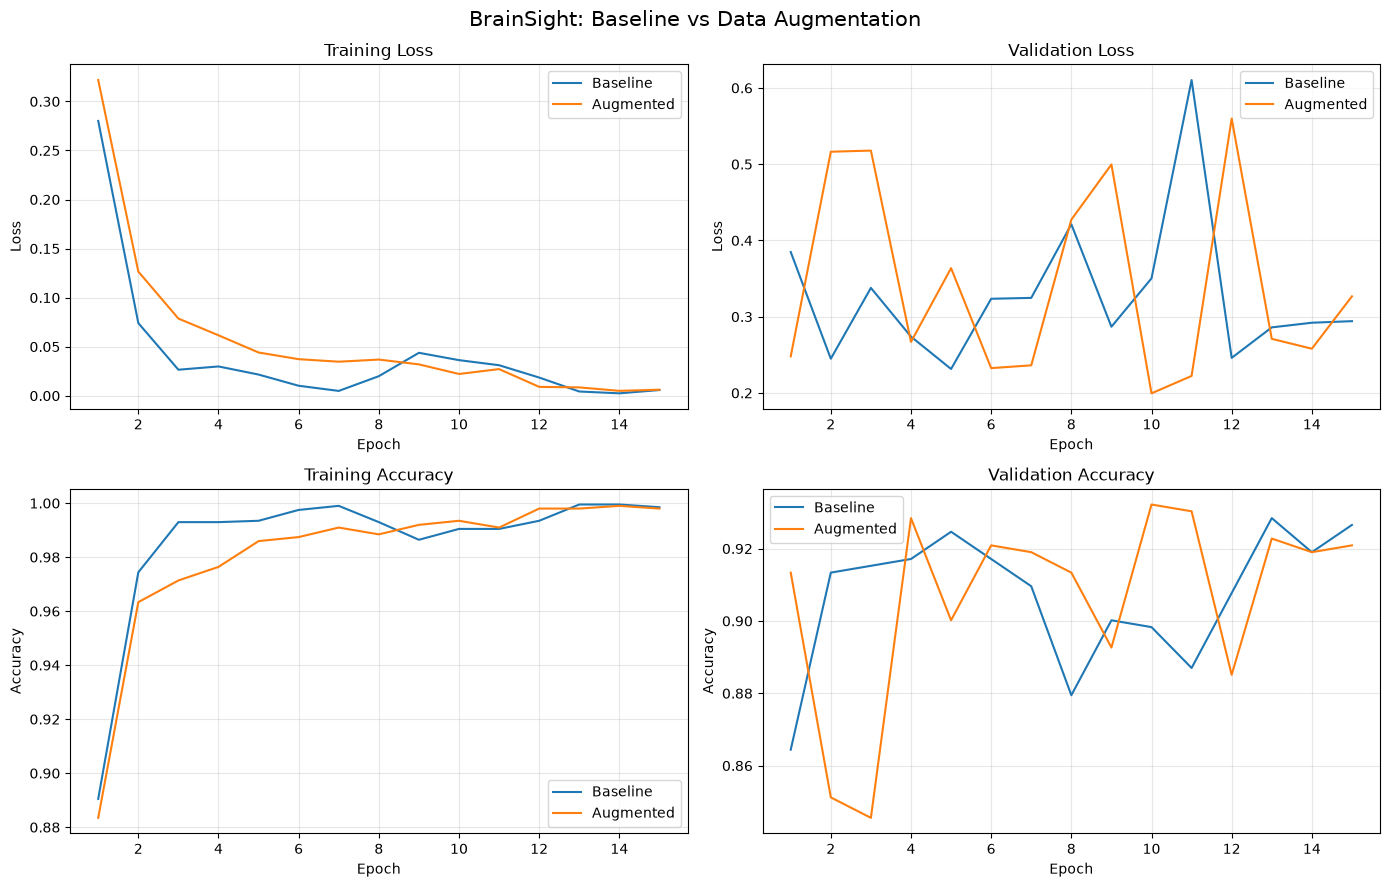

In [121]:
import matplotlib.pyplot as plt

epochs = range(1, 16)

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# Training loss
axes[0, 0].plot(epochs, history["train_loss"], label="Baseline")
axes[0, 0].plot(epochs, history_exp["train_loss"], label="Augmented")
axes[0, 0].set_title("Training Loss")
axes[0, 0].set_xlabel("Epoch")
axes[0, 0].set_ylabel("Loss")
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3)

# Validation loss
axes[0, 1].plot(epochs, history["val_loss"], label="Baseline")
axes[0, 1].plot(epochs, history_exp["val_loss"], label="Augmented")
axes[0, 1].set_title("Validation Loss")
axes[0, 1].set_xlabel("Epoch")
axes[0, 1].set_ylabel("Loss")
axes[0, 1].legend()
axes[0, 1].grid(alpha=0.3)

# Training accuracy
axes[1, 0].plot(epochs, history["train_accuracy"], label="Baseline")
axes[1, 0].plot(epochs, history_exp["train_accuracy"], label="Augmented")
axes[1, 0].set_title("Training Accuracy")
axes[1, 0].set_xlabel("Epoch")
axes[1, 0].set_ylabel("Accuracy")
axes[1, 0].legend()
axes[1, 0].grid(alpha=0.3)

# Validation accuracy
axes[1, 1].plot(epochs, history["val_accuracy"], label="Baseline")
axes[1, 1].plot(epochs, history_exp["val_accuracy"], label="Augmented")
axes[1, 1].set_title("Validation Accuracy")
axes[1, 1].set_xlabel("Epoch")
axes[1, 1].set_ylabel("Accuracy")
axes[1, 1].legend()
axes[1, 1].grid(alpha=0.3)

plt.suptitle("BrainSight: Baseline vs Data Augmentation", fontsize=15)
plt.tight_layout()
plt.show()